# Fraud Model Evaluation Report

**Question:** how good is the deployed fraud model, honestly, and why?

Everything here is produced by `python -m training.evaluate`. This notebook only *reads* the saved
results (`docs/evaluation/metrics.json`) and explains them, so it reruns instantly and never retrains.

**Setup.** Transactions are split by time: train on Jan 1 – Aug 5, validation on Aug 5 – 30, and
test on Aug 30 – Dec 16. Early stopping and the threshold choice use validation only. The test
period is scored once. Every PR-AUC comes with a bootstrap 95% confidence interval (resampling
the test rows 500 times).

In [1]:
import json, pathlib
import pandas as pd
from IPython.display import Image, display

EVAL = pathlib.Path("../docs/evaluation")
m = json.loads((EVAL / "metrics.json").read_text())
pd.DataFrame(m["splits"]).T

,rows,from,to,fraud_rate
train,105778,2015-01-01 00:00:44,2015-08-05 11:06:39,0.1142
validation,15111,2015-08-05 11:07:00,2015-08-30 15:18:18,0.0453
test,30223,2015-08-30 15:18:56,2015-12-16 02:56:05,0.046


## 1. The headline: the model barely beats random guessing

**PR-AUC** (area under the precision-recall curve) is the main metric for rare-event problems. A
model that guesses randomly scores the fraud rate, 0.046 here; a perfect model scores 1.0.
**Recall at 5% alerts** answers: if analysts review the top 5% of transactions by score, what
share of all fraud do they catch?

In [2]:
rows = []
for name, r in m["models"].items():
    t = r["test"]
    rows.append({
        "model": name,
        "PR-AUC": t["pr_auc"],
        "PR-AUC 95% CI": t.get("pr_auc_ci95"),
        "ROC-AUC": t["roc_auc"],
        "recall @ 5% alerts": (t.get("at_5pct_alerts") or {}).get("recall"),
        "precision @ 50% recall": t.get("precision_at_50pct_recall"),
    })
pd.DataFrame(rows).set_index("model").sort_values("PR-AUC", ascending=False)

,PR-AUC,PR-AUC 95% CI,ROC-AUC,recall @ 5% alerts,precision @ 50% recall
model,,,,,
deployed_model,0.0911,"[0.0804, 0.1051]",0.5621,0.1569,0.0558
xgboost/all_train_data,0.0884,"[0.079, 0.1011]",0.5615,0.1591,0.0539
xgboost/without_bot_burst,0.0884,"[0.0783, 0.1015]",0.5619,0.1548,0.0510
random_forest/all_train_data,0.0860,"[0.0771, 0.098]",0.5622,0.1548,0.0542
random_forest/without_bot_burst,0.0850,"[0.0758, 0.0969]",0.5570,0.1497,0.0538
logistic_regression/without_bot_burst,0.0772,"[0.0692, 0.0888]",0.5544,0.1325,0.0532
logistic_regression/all_train_data,0.0492,"[0.0458, 0.0542]",0.4987,0.0677,0.0464
base_rate,0.0460,None,0.5000,NaN,NaN


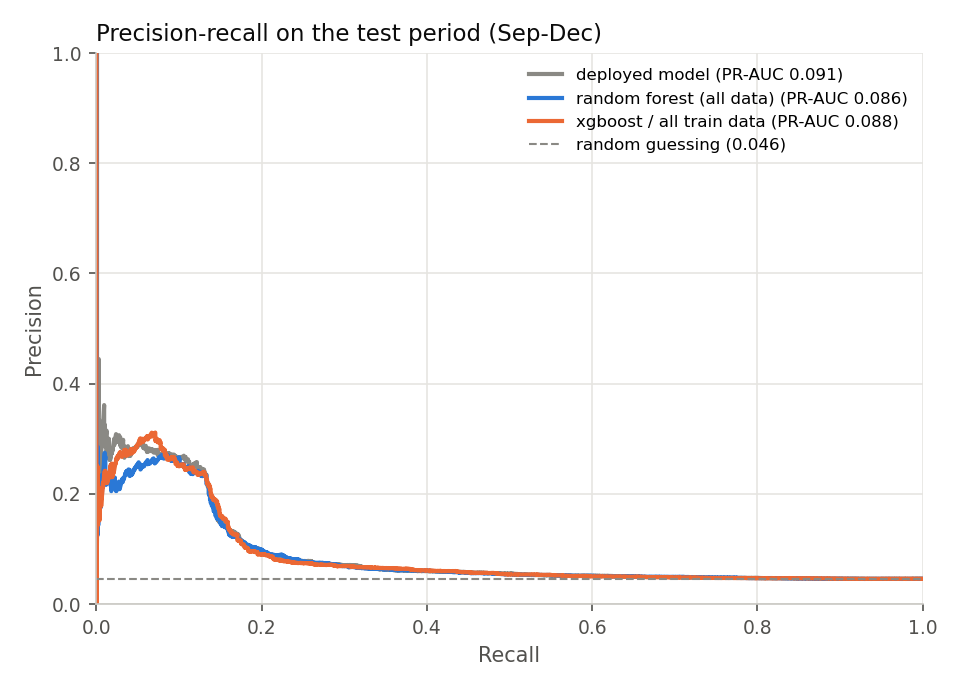

In [3]:
display(Image(EVAL / "pr_curves_test.png"))

**Reading it:**
- Every tree model lands around PR-AUC 0.09, about 2× random. All of their confidence intervals
  overlap, so none is truly better than the others.
- Logistic regression trained on all data scores *at* random (0.049, ROC 0.50).
- Every curve sinks to the random-guessing line past about 20% recall. The model finds a small
  group of obvious fraud, then has nothing left to go on.

## 2. Why: half the features are always zero

Every user in the dataset makes exactly **one** transaction. So any feature counted per user
("how many purchases has this user made in 7 days?") is always 0 when the model sees it.
A feature that never changes can't teach the model anything.

In [4]:
d = m["diagnostics"]
print(f"Users with >1 transaction: {d['users_with_more_than_one_txn']}")
print(f"Constant features: {d['n_constant_features']} of {d['n_served_features']}")
d["constant_features_in_train"]

Users with >1 transaction: 0
Constant features: 25 of 52


['uid_did_2h',
 'uid_did_24h',
 'uid_did_7d',
 'uid_did_30d',
 'uid_did_90d',
 'purchase_cnt_24h',
 'purchase_amt_24h',
 'purchase_cnt_7d',
 'purchase_amt_7d',
 'purchase_cnt_30d',
 'purchase_amt_30d',
 'purchase_cnt_90d',
 'purchase_amt_90d',
 'purchase_success_cnt_24h',
 'purchase_success_amt_24h',
 'purchase_success_cnt_7d',
 'purchase_success_amt_7d',
 'purchase_success_cnt_30d',
 'purchase_success_amt_30d',
 'purchase_success_cnt_90d',
 'purchase_success_amt_90d',
 'did_uid_days_on_file',
 'pur_median_amt_90d',
 'time_since_last_txn_uid',
 'high_amount_vs_hist']

## 3. Why: January was a one-off bot attack

January's fraud rate is about 76%; every other month is around 4–5%. Most of January's fraud is
purchases made **within 1 second of signup**, which is bot behaviour. That pattern never appears
in the test period. So the model spends much of its effort learning a pattern that is already over.

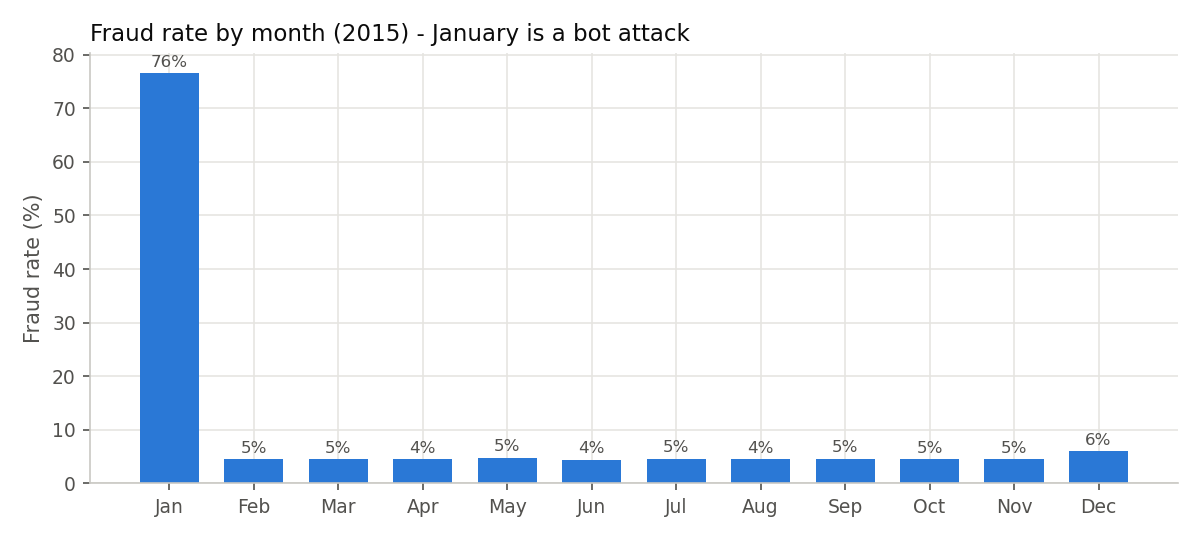

definition              purchase within 1 second of signup
rows_total                                            7600
fraud_rate                                             1.0
share_of_train_fraud                                0.6293
rows_in_test                                             0
dtype: object

In [5]:
display(Image(EVAL / "fraud_by_month.png"))
pd.Series(d["bot_burst"])

The XGBoost feature importances confirm it. `month_of_year` ranks 3rd, even though the test
months (Sep–Dec) never appear in training. The model has partly learned "January = fraud".

The useful signals are **device sharing** (`did_uid_*`: how many different users one device was
used by) and **IP sharing** (`ip_uid_*`).

In [6]:
pd.Series(m["models"]["xgboost/all_train_data"]["top_features"], name="importance")

days_since_signup        0.3214
did_uid_7d               0.1885
month_of_year            0.1823
did_uid_90d              0.1012
did_txn_cnt_2h           0.0642
did_uid_2h               0.0456
ip_uid_2h                0.0339
did_uid_30d              0.0128
did_txn_cnt_30d          0.0098
country_txn_count_30d    0.0048
Name: importance, dtype: float64

**Does removing the bot burst help?** We retrained without the 1-second purchases. The tree
models barely change (XGBoost 0.088 → 0.088), because they handle the January cluster in a few
splits. Logistic regression improves a lot (0.049 → 0.077), because one extreme cluster tilts a
single straight-line boundary.

## 4. Choosing the decision threshold by cost

A model outputs a score; the **threshold** turns it into allow / deny. Instead of guessing (the
API uses 0.7), we pick the threshold that minimises dollars lost:

- every alert costs a **$5 manual review**
- every missed fraud costs its **purchase value**

The threshold is chosen on **validation**, then checked on **test**.

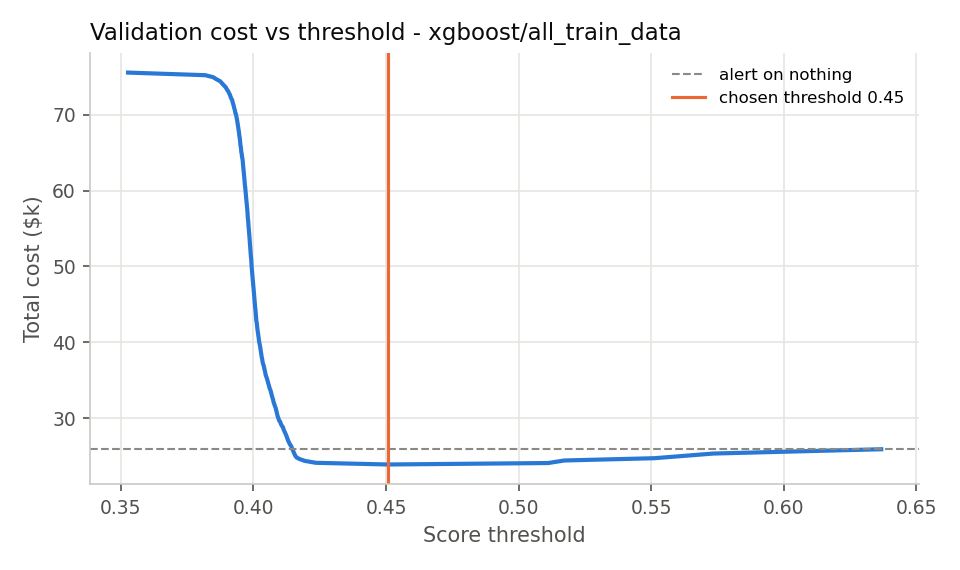

In [7]:
display(Image(EVAL / "cost_vs_threshold.png"))

In [8]:
t = m["threshold"]
print(f"Fraud in test period if we alert on nothing: ${t['cost_of_alerting_on_nothing']:,.0f}")
pd.DataFrame({k: t[k] for k in ["best_model_at_chosen_threshold",
                                "best_model_at_served_threshold",
                                "deployed_model_at_served_threshold"]}).T

Fraud in test period if we alert on nothing: $51,395


,threshold,total_cost,alerts,fraud_caught,fraud_total,saved_vs_nothing
best_model_at_chosen_threshold,0.4507,48304.0,790.0,184.0,1389.0,3091.0
best_model_at_served_threshold,0.7000,51395.0,0.0,0.0,1389.0,0.0
deployed_model_at_served_threshold,0.7000,51280.0,10.0,4.0,1389.0,115.0


**Reading it:**
- At today's threshold of 0.7, the deployed model flags 10 transactions and catches 4 frauds.
  In practice it allows everything.
- The cost-chosen threshold (about 0.45) flags 790 transactions, catches 184 frauds, and saves
  about $3.1k (6% of fraud losses). That's a real improvement, but a small one, because the
  model itself is weak.
- XGBoost's scores sit between about 0.35 and 0.65 (see the cost chart's x-axis). They are not
  calibrated probabilities, so "0.45" doesn't mean a 45% chance of fraud. Calibration is the
  next step.

## 5. Bug found along the way: training-serving skew

Training encoded `sex` as M=0 / F=1; the live API encoded it as F=0 / M=1. Every live request
fed the model the opposite value. This is now fixed, and `tests/test_encoding_contract.py`
fails if the two encodings ever drift apart again.

## What's next

1. **Features that work for one-time users:** seconds from signup to purchase, plus more
   device and IP sharing signals. Drop the 25 constant features and `month_of_year`.
2. **Calibration**, so scores mean real probabilities and the threshold is stable.
3. **Drift monitoring.** January shows how quickly fraud patterns shift.